In [1]:
#Import libraries
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import os

In [13]:
# Reading dataset 
df = pd.read_csv('./CrisisMMD_v2.0/annotations/california_wildfires_final_data.tsv', sep='\t')

df.head(5)

,tweet_id,image_id,text_info,text_info_conf,image_info,image_info_conf,text_human,text_human_conf,image_human,image_human_conf,image_damage,image_damage_conf,tweet_text,image_url,image_path
0,917791044158185473,917791044158185473_0,informative,1.0000,informative,0.6766,other_relevant_information,1.0000,other_relevant_information,0.6766,NaN,NaN,RT @Gizmodo: Wildfires raging through Northern...,http://pbs.twimg.com/media/DLyi_WYVYAApwNg.jpg,data_image/california_wildfires/10_10_2017/917...
1,917791130590183424,917791130590183424_0,informative,1.0000,informative,0.6667,infrastructure_and_utility_damage,1.0000,affected_individuals,0.6667,NaN,NaN,PHOTOS: Deadly wildfires rage in California ht...,http://pbs.twimg.com/media/DLymKm9UMAAu0qw.jpg,data_image/california_wildfires/10_10_2017/917...
2,917791291823591425,917791291823591425_0,informative,0.6813,informative,1.0000,other_relevant_information,0.6813,infrastructure_and_utility_damage,1.0000,severe_damage,1.0,RT @Cal_OES: PLS SHARE: Weâ€™re capturing wild...,http://pbs.twimg.com/media/DLudaaZV4AAjT7x.jpg,data_image/california_wildfires/10_10_2017/917...
3,917791291823591425,917791291823591425_1,informative,0.6813,not_informative,1.0000,other_relevant_information,0.6813,not_humanitarian,1.0000,NaN,NaN,RT @Cal_OES: PLS SHARE: Weâ€™re capturing wild...,http://pbs.twimg.com/media/DLudaZXUMAABAEZ.jpg,data_image/california_wildfires/10_10_2017/917...
4,917792092100988929,917792092100988929_0,informative,0.6727,informative,0.6612,other_relevant_information,0.6727,infrastructure_and_utility_damage,0.6612,severe_damage,1.0,RT @TIME: California's raging wildfires as you...,http://pbs.twimg.com/media/DLwNe-NXUAE0XCw.jpg,data_image/california_wildfires/10_10_2017/917...


In [14]:
# merged all tsv file into dataframe with extra label "diaster_label" for better preprocessing 

base_path = './CrisisMMD_v2.0'
annotations_dir = os.path.join(base_path, 'annotations')

all_dataframes = []

for filename in os.listdir(annotations_dir):
    if filename.endswith('.tsv') and not filename.startswith('._'):
        file_path = os.path.join(annotations_dir, filename)
        
        temp_df = pd.read_csv(file_path, sep='\t')
        
        disaster_label = filename.replace('_final_data.tsv', '')
        temp_df['disaster_type'] = disaster_label
        
        all_dataframes.append(temp_df)

master_df = pd.concat(all_dataframes, ignore_index=True)

print(f"Total rows merged: {len(master_df)}")
print(master_df['disaster_type'].value_counts())

Total rows merged: 18082
disaster_type
hurricane_maria         4556
hurricane_irma          4504
hurricane_harvey        4434
california_wildfires    1589
mexico_earthquake       1380
srilanka_floods         1022
iraq_iran_earthquake     597
Name: count, dtype: int64


In [ ]:
master_df.head(5)

,tweet_id,image_id,text_info,text_info_conf,image_info,image_info_conf,text_human,text_human_conf,image_human,image_human_conf,image_damage,image_damage_conf,tweet_text,image_url,image_path,disaster_type
0,917791044158185473,917791044158185473_0,informative,1.0,informative,0.6766,other_relevant_information,1.0,other_relevant_information,0.6766,NaN,NaN,RT @Gizmodo: Wildfires raging through Northern...,http://pbs.twimg.com/media/DLyi_WYVYAApwNg.jpg,data_image/california_wildfires/10_10_2017/917...,california_wildfires


Tweet Index: 45 | Event: california_wildfires
TEXT: RT @monizcardozo: California wildfires: Residents find devastation in Santa Rosa https://t.co/3fuGJ5lW3t https://t.co/hNuXFATeh8
LABEL (Text): other_relevant_information
url: http://pbs.twimg.com/media/DLy5u7IVwAAaO3e.jpg
path: data_image/california_wildfires/10_10_2017/917815168825995264_0.jpg
imaqge hash: dbb099e39597e6809d280a20d9c776f1
LABEL (Image): vehicle_damage





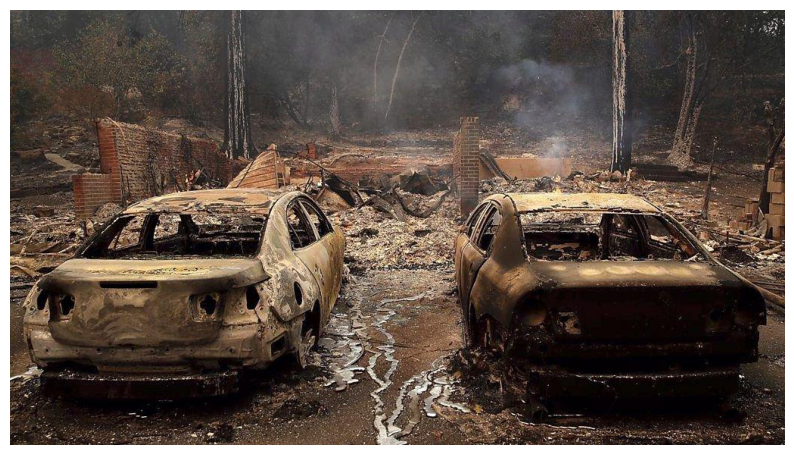

In [17]:
#Display text and tweet image
import hashlib

def display_tweet(df, index):

    if index >= len(df):
        print("Index out of range!")
        return

    row = df.iloc[index]
    
    tweet_text = row['tweet_text']
    img_rel_path = row['image_path']
    
    full_img_path = os.path.join(base_path, img_rel_path)

    def get_image_hash(fname):
        hash_md5 = hashlib.md5()
        try:
            with open(fname, "rb") as f:
                for chunk in iter(lambda: f.read(4096), b""):
                    hash_md5.update(chunk)
            return hash_md5.hexdigest()
        except FileNotFoundError:
            return None

    image_hash = get_image_hash(full_img_path)
    

    print(f"Tweet Index: {index} | Event: {row['disaster_type']}")
    print(f"TEXT: {tweet_text}")
    print(f"LABEL (Text): {row['text_human']}")
    print(f"url: {row['image_url']}")
    print(f"path: {row['image_path']}")
    print(f"imaqge hash: {image_hash}")
    print(f"LABEL (Image): {row['image_human']}")
    print("\n\n")
    
    if os.path.exists(full_img_path):
        img = Image.open(full_img_path)
        plt.figure(figsize=(10, 6))
        plt.imshow(img)
        plt.axis('off')
        plt.show()
    else:
        print(f"Error: image not found at {full_img_path}")

display_tweet(master_df, 45)

In [19]:
df["text_human"].unique()

array(['other_relevant_information', 'infrastructure_and_utility_damage',
       'injured_or_dead_people', 'not_humanitarian',
       'missing_or_found_people',
       'rescue_volunteering_or_donation_effort', 'affected_individuals',
       'vehicle_damage'], dtype=object)

In [20]:
# Tweet Index: 43 | Event: california_wildfires
# TEXT: RT @TheAtlantic: Photos of California's destructive wildfires, via @TheAtlPhoto: https://t.co/mzYsQALqrl https://t.co/bWvczIJa2Z
# LABEL (Text): infrastructure_and_utility_damage
# LABEL (Text): http://pbs.twimg.com/media/DLy7qk8WsAI8aOA.jpg
# LABEL (Text): data_image/california_wildfires/10_10_2017/917815040962695168_1.jpg
# LABEL (Image): vehicle_damage

In [21]:
# Tweet Index: 45 | Event: california_wildfires
# TEXT: RT @monizcardozo: California wildfires: Residents find devastation in Santa Rosa https://t.co/3fuGJ5lW3t https://t.co/hNuXFATeh8
# LABEL (Text): other_relevant_information
# LABEL (Text): http://pbs.twimg.com/media/DLy5u7IVwAAaO3e.jpg
# LABEL (Text): data_image/california_wildfires/10_10_2017/917815168825995264_0.jpg
# LABEL (Image): vehicle_damage


Tweet Index: 45 | Event: california_wildfires
TEXT: RT @monizcardozo: California wildfires: Residents find devastation in Santa Rosa https://t.co/3fuGJ5lW3t https://t.co/hNuXFATeh8
LABEL (Text): other_relevant_information
URL: http://pbs.twimg.com/media/DLy5u7IVwAAaO3e.jpg
Path: data_image/california_wildfires/10_10_2017/917815168825995264_0.jpg
Image Hash: dbb099e39597e6809d280a20d9c776f1
LABEL (Image): vehicle_damage




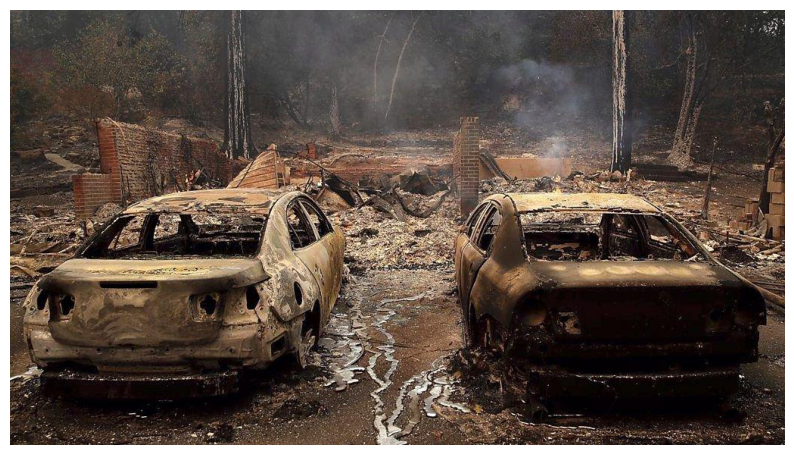

In [22]:
import hashlib

# Define this outside so it's a reusable tool
def get_image_hash(fname):
    hash_md5 = hashlib.md5()
    try:
        with open(fname, "rb") as f:
            for chunk in iter(lambda: f.read(4096), b""):
                hash_md5.update(chunk)
        return hash_md5.hexdigest()
    except FileNotFoundError:
        return None

def display_tweet(df, index):
    if index >= len(df):
        print("Index out of range!")
        return

    row = df.iloc[index]
    tweet_text = row['tweet_text']
    img_rel_path = row['image_path']
    
    # Ensure base_path is defined globally or inside here
    full_img_path = os.path.join(base_path, img_rel_path)

    # Call the helper function
    image_hash = get_image_hash(full_img_path)

    print(f"Tweet Index: {index} | Event: {row['disaster_type']}")
    print(f"TEXT: {tweet_text}")
    print(f"LABEL (Text): {row['text_human']}")
    print(f"URL: {row['image_url']}")
    print(f"Path: {row['image_path']}")
    print(f"Image Hash: {image_hash}")
    print(f"LABEL (Image): {row['image_human']}")
    print("\n")
    
    if os.path.exists(full_img_path):
        img = Image.open(full_img_path)
        plt.figure(figsize=(10, 6))
        plt.imshow(img)
        plt.axis('off')
        plt.show()
    else:
        print(f"Error: image not found at {full_img_path}")

# Run it
display_tweet(master_df, 45)

Tweet Index: 45 | Event: california_wildfires
TEXT: RT @monizcardozo: California wildfires: Residents find devastation in Santa Rosa https://t.co/3fuGJ5lW3t https://t.co/hNuXFATeh8
LABEL (Text): other_relevant_information
URL: http://pbs.twimg.com/media/DLy5u7IVwAAaO3e.jpg
Path: data_image/california_wildfires/10_10_2017/917815168825995264_0.jpg
Image Hash: dbb099e39597e6809d280a20d9c776f1
LABEL (Image): vehicle_damage




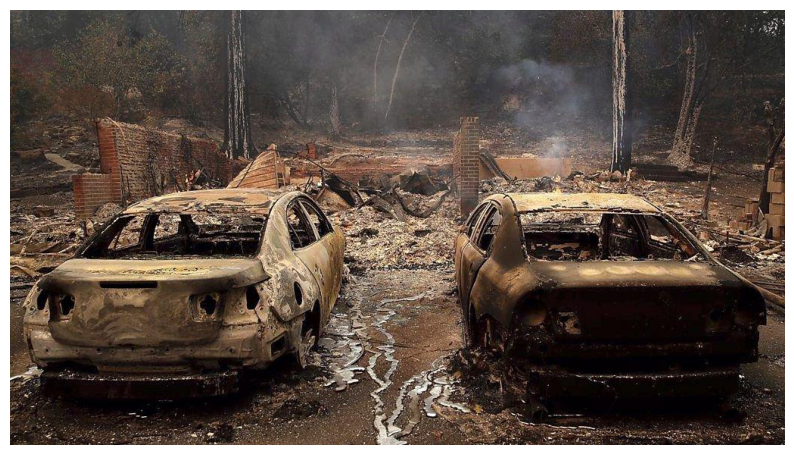

In [23]:
import hashlib

# Define this outside so it's a reusable tool
def get_image_hash(fname):
    hash_md5 = hashlib.md5()
    try:
        with open(fname, "rb") as f:
            for chunk in iter(lambda: f.read(4096), b""):
                hash_md5.update(chunk)
        return hash_md5.hexdigest()
    except FileNotFoundError:
        return None

def display_tweet(df, index):
    if index >= len(df):
        print("Index out of range!")
        return

    row = df.iloc[index]
    tweet_text = row['tweet_text']
    img_rel_path = row['image_path']
    
    # Ensure base_path is defined globally or inside here
    full_img_path = os.path.join(base_path, img_rel_path)

    # Call the helper function
    image_hash = get_image_hash(full_img_path)

    print(f"Tweet Index: {index} | Event: {row['disaster_type']}")
    print(f"TEXT: {tweet_text}")
    print(f"LABEL (Text): {row['text_human']}")
    print(f"URL: {row['image_url']}")
    print(f"Path: {row['image_path']}")
    print(f"Image Hash: {image_hash}")
    print(f"LABEL (Image): {row['image_human']}")
    print("\n")
    
    if os.path.exists(full_img_path):
        img = Image.open(full_img_path)
        plt.figure(figsize=(10, 6))
        plt.imshow(img)
        plt.axis('off')
        plt.show()
    else:
        print(f"Error: image not found at {full_img_path}")

# Run it
display_tweet(master_df, 45)

In [25]:
def add_hash_column(df, base_path):
    hashes = []
    for _, row in df.iterrows():
        full_path = os.path.join(base_path, row["image_path"])
        hashes.append(get_image_hash(full_path))
    df["image_hash"] = hashes
    return df

master_df = add_hash_column(master_df, base_path)

duplicate_hashes = (
    master_df["image_hash"]
    .value_counts()
    .loc[lambda x: x > 1]
)

duplicate_df = master_df[
    master_df["image_hash"].isin(duplicate_hashes.index)
]


print(duplicate_df.head(5))
print(f"Number of duplicate Images: {len(duplicate_df)}")




              tweet_id              image_id    text_info  text_info_conf  \
8   917793137925459968  917793137925459968_1  informative          1.0000   
20  917796280377602048  917796280377602048_0  informative          1.0000   
35  917806204012978176  917806204012978176_0  informative          1.0000   
36  917807529479901184  917807529479901184_0  informative          0.6667   
54  917820422011449345  917820422011449345_0  informative          1.0000   

         image_info  image_info_conf                              text_human  \
8       informative           0.6538       infrastructure_and_utility_damage   
20      informative           0.6897                  injured_or_dead_people   
35  not_informative           1.0000                  injured_or_dead_people   
36      informative           0.7587  rescue_volunteering_or_donation_effort   
54      informative           1.0000                  injured_or_dead_people   

    text_human_conf                             image_hu